# UTS Penambangan Data — Decision Tree
**Klasifikasi Tingkat Intensitas Konsumsi Listrik per Cabang (UP3) PLN di Provinsi DKI Jakarta**

- Mahasiswa: Hexa — NIM 202431018 — Teknik Informatika, Institut Teknologi PLN
- Dataset: *Jumlah Pelanggan dan Jumlah Daya Terjual menurut Cabang di Provinsi DKI Jakarta* (Satu Data Jakarta, periode 2020–2025)
- Algoritma: **Decision Tree (CART, kriteria Gini)**

**Skenario.** Perencana jaringan PLN perlu mengetahui cabang mana yang tahun depan akan masuk kategori konsumsi *Rendah / Sedang / Tinggi* (kWh per pelanggan) agar kapasitas trafo dan alokasi pemeliharaan dapat disiapkan lebih awal. Model memakai data tahun *t* untuk memprediksi kelas intensitas tahun *t+1*.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
plt.rcParams['figure.dpi']=110

## 1. Memuat data
Berkas `.xls` dari portal ternyata berisi tabel HTML, sehingga dibaca dengan `read_html` (dengan cadangan `read_excel`).

In [2]:
FILE = 'jumlah-pelanggan-dan-jumlah-daya-terjual-menurut-cabang-di-provinsi-dki-jakarta-komponen-data.xls'
try:
    df = pd.read_html(FILE)[0]
except Exception:
    df = pd.read_excel(FILE)
df.columns = ['tahun','cabang','pel','daya']      # pel = jumlah pelanggan, daya = daya terjual (kWh)
df = df.sort_values(['cabang','tahun']).reset_index(drop=True)
print('Ukuran data:', df.shape)
df.head(10)

Ukuran data: (96, 4)


,tahun,cabang,pel,daya
0,2020,BANDENGAN,353017,3437177148
1,2021,BANDENGAN,366517,3465397471
2,2022,BANDENGAN,378835,3884546863
3,2023,BANDENGAN,393390,4444580602
4,2024,BANDENGAN,41014,5534925144
5,2025,BANDENGAN,425334,4326640994
6,2020,BINTARO,458919,1800477116
7,2021,BINTARO,473413,1821949308
8,2022,BINTARO,486132,1868169087
9,2023,BINTARO,499817,1881231322


## 2. EDA awal

In [3]:
print(df.dtypes, '\n')
print('Missing value per kolom:\n', df.isna().sum(), '\n')
print('Baris duplikat:', df.duplicated().sum())
print('Jumlah cabang:', df.cabang.nunique(), '| Tahun:', sorted(df.tahun.unique()))
df[['pel','daya']].describe().round(0)

tahun     int64
cabang      str
pel       int64
daya      int64
dtype: object 

Missing value per kolom:
 tahun     0
cabang    0
pel       0
daya      0
dtype: int64 

Baris duplikat: 0
Jumlah cabang: 16 | Tahun: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,pel,daya
count,96.0,9.600000e+01
mean,301997.0,2.217383e+09
std,118378.0,1.187130e+09
min,17992.0,7.209878e+08
25%,227793.0,1.458761e+09
50%,304956.0,1.728801e+09
75%,394410.0,2.704279e+09
max,528303.0,5.536430e+09


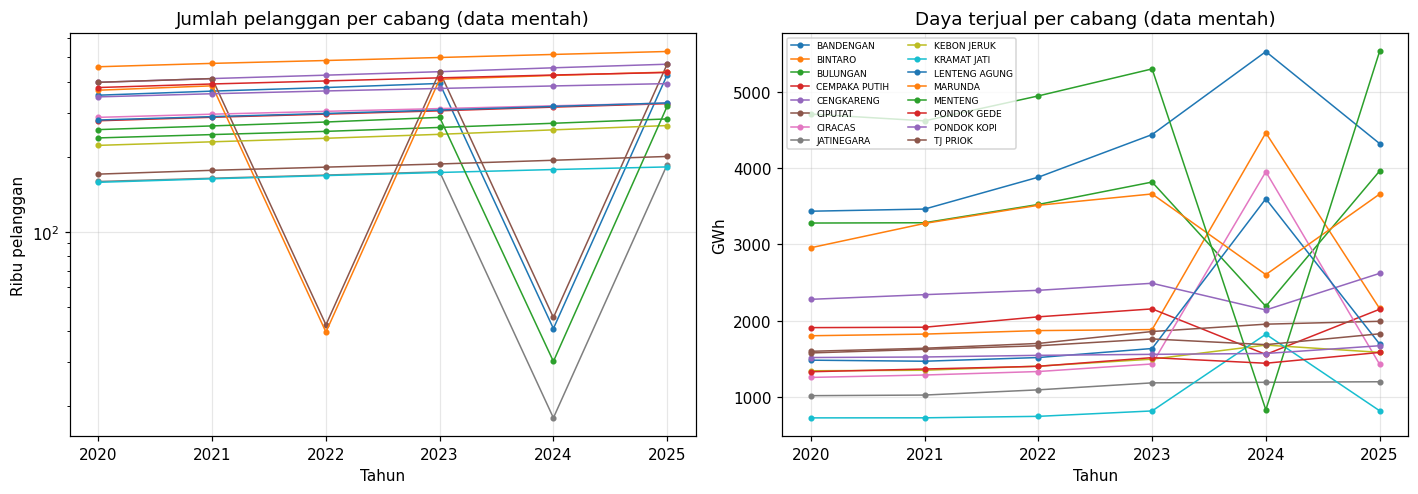

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13,4.6))
for cab, g in df.groupby('cabang'):
    ax[0].plot(g.tahun, g.pel/1000, marker='o', ms=3, lw=1)
    ax[1].plot(g.tahun, g.daya/1e6, marker='o', ms=3, lw=1, label=cab)
ax[0].set_title('Jumlah pelanggan per cabang (data mentah)'); ax[0].set_ylabel('Ribu pelanggan'); ax[0].set_yscale('log')
ax[1].set_title('Daya terjual per cabang (data mentah)'); ax[1].set_ylabel('GWh')
ax[1].legend(fontsize=6, ncol=2)
for a in ax: a.set_xlabel('Tahun'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figs/fig1_raw.png', dpi=150); plt.show()

Pada grafik kiri tampak titik yang **jatuh sepuluh kali lipat** (nilai pelanggan kehilangan satu digit). Pada grafik kanan tahun **2024** tampak zig-zag: urutan cabang terbesar–terkecil berubah drastis dibanding tahun-tahun lain. Keduanya bukan perilaku wajar.

## 3. Deteksi nilai tidak valid (setara *missing value*) dan *outlier*

In [5]:
# (a) Metode IQR global — hanya sebagai pembanding
def iqr_flag(s):
    q1, q3 = s.quantile([.25,.75]); i = q3-q1
    return (s < q1-1.5*i) | (s > q3+1.5*i)
print('IQR global pada daya :', iqr_flag(df.daya).sum(), 'baris ->', sorted(df[iqr_flag(df.daya)].cabang.unique()))
print('IQR global pada pel  :', iqr_flag(df.pel).sum(), 'baris')

IQR global pada daya : 6 baris -> ['BANDENGAN', 'MENTENG']
IQR global pada pel  : 0 baris


In [6]:
# (b) Metode berbasis median per cabang (membandingkan nilai dengan deret waktu cabangnya sendiri)
med_p = df.groupby('cabang').pel.transform('median')
med_d = df.groupby('cabang').daya.transform('median')
df['inv_pel']  = df.pel < 0.30*med_p                       # pelanggan < 30% median cabang  -> tidak valid
df['out_daya'] = (df.daya - med_d).abs()/med_d > 0.20      # menyimpang > 20% dari median cabang -> outlier
print('Pelanggan tidak valid :', df.inv_pel.sum(),  f'({df.inv_pel.mean()*100:.2f}% baris)')
print('Daya outlier          :', df.out_daya.sum(), f'({df.out_daya.mean()*100:.2f}% baris)')
df[df.inv_pel | df.out_daya][['tahun','cabang','pel','daya','inv_pel','out_daya']]

Pelanggan tidak valid : 6 (6.25% baris)
Daya outlier          : 9 (9.38% baris)


,tahun,cabang,pel,daya,inv_pel,out_daya
4,2024,BANDENGAN,41014,5534925144,True,True
10,2024,BINTARO,514108,4466914225,False,True
16,2024,BULUNGAN,272489,2186764919,False,True
22,2024,CEMPAKA PUTIH,316208,1554698823,False,True
32,2022,CIPUTAT,42449,1699261561,True,False
34,2024,CIPUTAT,45417,1952531402,True,False
40,2024,CIRACAS,320163,3955909654,False,True
46,2024,JATINEGARA,17992,1188570873,True,False
58,2024,KRAMAT JATI,177794,1820403614,False,True
64,2024,LENTENG AGUNG,318257,3601034546,False,True


**Catatan.** Dataset ini tidak memiliki sel kosong (`NaN`). Namun, 6 nilai `pel` jelas tidak valid (kehilangan satu digit) dan 9 nilai `daya` pada tahun 2024 menyimpang dari pola cabangnya. Nilai-nilai tidak valid ini diperlakukan sebagai ***missing value*** (diubah menjadi `NaN`) lalu diimputasi. IQR global tidak dipakai sebagai penentu karena menandai 6 baris, yaitu Menteng pada lima tahun (nilai memang konsisten tinggi, bukan kesalahan data) dan Bandengan 2024, sehingga hanya menangkap 1 dari 9 anomali 2024; sisanya masih berada di dalam rentang global.

## 4. Imputasi (interpolasi linear per cabang)

In [7]:
c = df.copy()
c['pel_c']  = c.pel.astype(float);  c.loc[c.inv_pel,  'pel_c']  = np.nan
c['daya_c'] = c.daya.astype(float); c.loc[c.out_daya, 'daya_c'] = np.nan
print('Missing sesudah penandaan  :', c[['pel_c','daya_c']].isna().sum().to_dict())
for k in ['pel_c','daya_c']:
    c[k] = c.groupby('cabang')[k].transform(lambda s: s.interpolate(limit_direction='both'))
print('Missing sesudah imputasi   :', c[['pel_c','daya_c']].isna().sum().to_dict())
c.loc[c.inv_pel | c.out_daya, ['tahun','cabang','pel','pel_c','daya','daya_c']].round(0)

Missing sesudah penandaan  : {'pel_c': 6, 'daya_c': 9}
Missing sesudah imputasi   : {'pel_c': 0, 'daya_c': 0}


,tahun,cabang,pel,pel_c,daya,daya_c
4,2024,BANDENGAN,41014,409362.0,5534925144,4.385611e+09
10,2024,BINTARO,514108,514108.0,4466914225,2.020377e+09
16,2024,BULUNGAN,272489,272489.0,2186764919,3.892706e+09
22,2024,CEMPAKA PUTIH,316208,316208.0,1554698823,2.150757e+09
32,2022,CIPUTAT,42449,424978.0,1699261561,1.699262e+09
34,2024,CIPUTAT,45417,454226.0,1952531402,1.952531e+09
40,2024,CIRACAS,320163,320163.0,3955909654,1.427933e+09
46,2024,JATINEGARA,17992,179951.0,1188570873,1.188571e+09
58,2024,KRAMAT JATI,177794,177794.0,1820403614,8.136020e+08
64,2024,LENTENG AGUNG,318257,318257.0,3601034546,1.662608e+09


## 5. Rekayasa fitur dan target

In [8]:
c['pel_k']    = c.pel_c/1000          # ribu pelanggan
c['daya_gwh'] = c.daya_c/1e6          # GWh
c['rasio']    = c.daya_c/c.pel_c      # kWh per pelanggan per tahun
c['kelas']    = pd.cut(c.rasio, [0,5000,9000,np.inf], labels=['Rendah','Sedang','Tinggi'])
c['target']   = c.groupby('cabang').kelas.shift(-1)       # kelas intensitas TAHUN BERIKUTNYA
m = c.dropna(subset=['target']).copy()                    # transisi 2020->2021 ... 2024->2025
print('Data model:', m.shape); print(m.target.value_counts())

Data model: (80, 13)
target
Rendah    31
Sedang    30
Tinggi    19
Name: count, dtype: int64


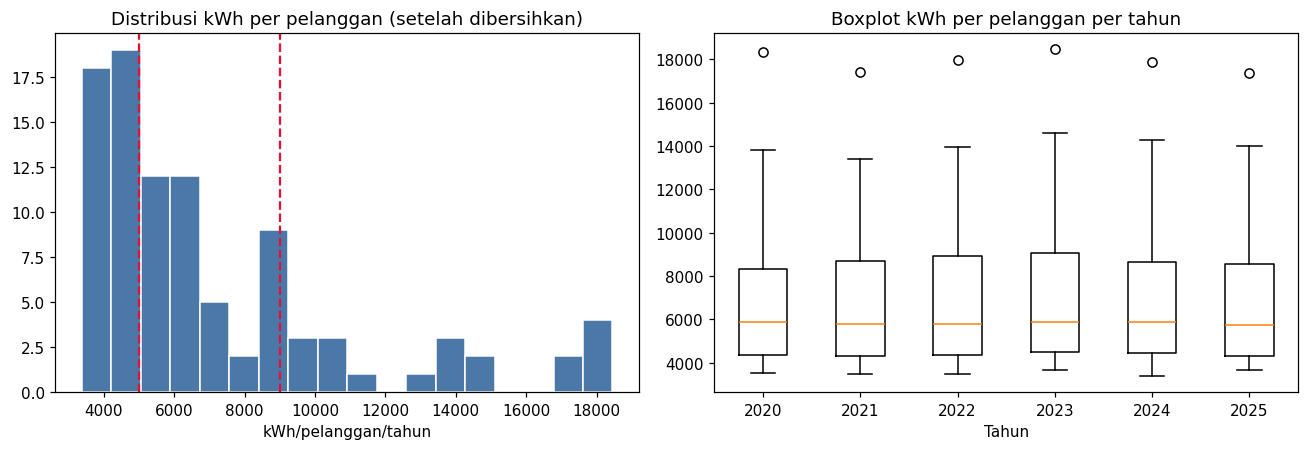

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12,4.2))
ax[0].hist(c.rasio, bins=18, color='#4C78A8', edgecolor='white')
for t in (5000, 9000): ax[0].axvline(t, color='crimson', ls='--')
ax[0].set_title('Distribusi kWh per pelanggan (setelah dibersihkan)'); ax[0].set_xlabel('kWh/pelanggan/tahun')
data=[g.rasio.values for _,g in c.groupby('tahun')]
ax[1].boxplot(data, labels=sorted(c.tahun.unique())); ax[1].set_title('Boxplot kWh per pelanggan per tahun'); ax[1].set_xlabel('Tahun')
plt.tight_layout(); plt.savefig('figs/fig2_clean.png', dpi=150); plt.show()

## 6. Pembagian data (berbasis waktu)
Data latih: fitur tahun 2020–2023 (target 2021–2024). Data uji: fitur tahun 2024 (target kelas 2025) — 16 cabang.

In [10]:
FITUR = ['pel_k','daya_gwh','rasio']
train = m[m.tahun <= 2023]; test = m[m.tahun == 2024]
X_tr, y_tr, X_te, y_te = train[FITUR], train.target.astype(str), test[FITUR], test.target.astype(str)
print('Latih:', X_tr.shape, '| Uji:', X_te.shape)

Latih: (64, 3) | Uji: (16, 3)


## 7. Pelatihan Decision Tree + pencarian hiperparameter

In [11]:
grid = {'max_depth':[1,2,3,4,5], 'min_samples_leaf':[1,2,3]}
gs = GridSearchCV(DecisionTreeClassifier(criterion='gini', random_state=42), grid,
                  cv=StratifiedKFold(4, shuffle=True, random_state=42), scoring='accuracy')
gs.fit(X_tr, y_tr)
model = gs.best_estimator_
print('Hiperparameter terbaik :', gs.best_params_)
print('Akurasi CV (data latih):', round(gs.best_score_, 4))

Hiperparameter terbaik : {'max_depth': 2, 'min_samples_leaf': 1}
Akurasi CV (data latih): 0.9688


## 8. Evaluasi

Akurasi data uji: 0.875 

              precision    recall  f1-score   support

      Rendah       0.86      1.00      0.92         6
      Sedang       0.83      0.83      0.83         6
      Tinggi       1.00      0.75      0.86         4

    accuracy                           0.88        16
   macro avg       0.90      0.86      0.87        16
weighted avg       0.88      0.88      0.87        16



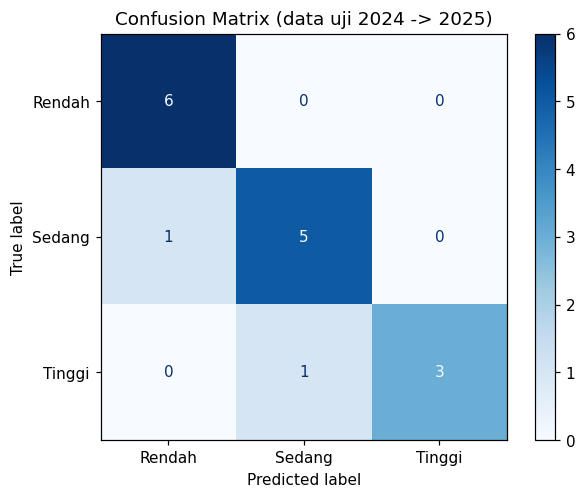

,cabang,rasio,aktual,prediksi,benar
4,BANDENGAN,10713.0,Tinggi,Tinggi,True
10,BINTARO,3930.0,Rendah,Rendah,True
16,BULUNGAN,14286.0,Tinggi,Tinggi,True
22,CEMPAKA PUTIH,6802.0,Sedang,Sedang,True
28,CENGKARENG,4706.0,Sedang,Rendah,False
34,CIPUTAT,4299.0,Rendah,Rendah,True
40,CIRACAS,4460.0,Rendah,Rendah,True
46,JATINEGARA,6605.0,Sedang,Sedang,True
52,KEBON JERUK,6544.0,Sedang,Sedang,True
58,KRAMAT JATI,4576.0,Rendah,Rendah,True


In [12]:
y_pred = model.predict(X_te)
print('Akurasi data uji:', round(accuracy_score(y_te, y_pred), 4), '\n')
print(classification_report(y_te, y_pred, labels=['Rendah','Sedang','Tinggi'], zero_division=0))
cm = confusion_matrix(y_te, y_pred, labels=['Rendah','Sedang','Tinggi'])
disp = ConfusionMatrixDisplay(cm, display_labels=['Rendah','Sedang','Tinggi'])
disp.plot(cmap='Blues'); plt.title('Confusion Matrix (data uji 2024 -> 2025)')
plt.savefig('figs/fig4_cm.png', dpi=150, bbox_inches='tight'); plt.show()
hasil = test[['cabang','rasio']].copy(); hasil['aktual']=y_te.values; hasil['prediksi']=y_pred; hasil['benar']=hasil.aktual==hasil.prediksi
hasil.round(0)

|--- rasio <= 4875.80
|   |--- class: Rendah
|--- rasio >  4875.80
|   |--- rasio <= 9068.22
|   |   |--- class: Sedang
|   |--- rasio >  9068.22
|   |   |--- class: Tinggi

Feature importance: {'pel_k': np.float64(0.0), 'daya_gwh': np.float64(0.0), 'rasio': np.float64(1.0)}


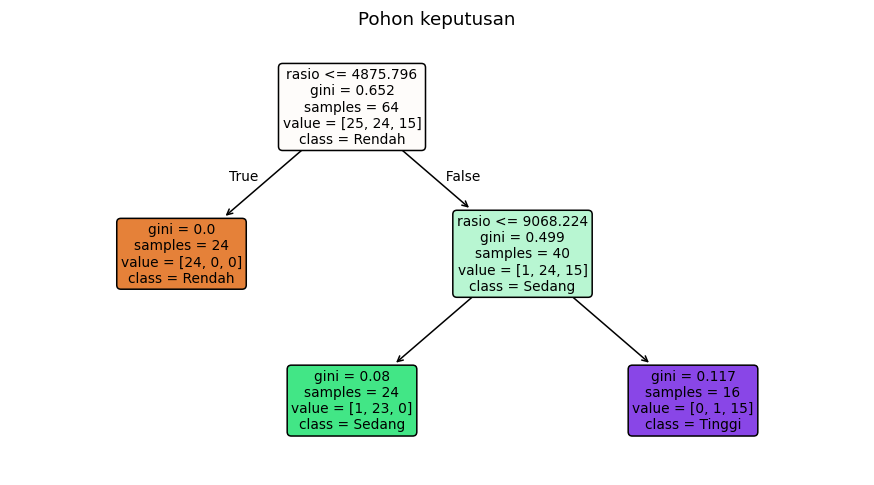

In [13]:
print(export_text(model, feature_names=FITUR))
print('Feature importance:', dict(zip(FITUR, model.feature_importances_.round(3))))
plt.figure(figsize=(10,5.2))
plot_tree(model, feature_names=FITUR, class_names=list(model.classes_), filled=True, rounded=True, fontsize=9)
plt.title('Pohon keputusan'); plt.savefig('figs/fig3_tree.png', dpi=150, bbox_inches='tight'); plt.show()

## 9. Verifikasi terhadap perhitungan manual (Soal 2)
Pohon dilatih pada 16 baris yang sama dengan hitungan manual (fitur 2024 → kelas 2025). Ambang batas harus sama dengan hasil manual (4.641,29 dan 8.668,92).

In [14]:
cek = DecisionTreeClassifier(criterion='gini', max_depth=2, random_state=42).fit(X_te, y_te)
print(export_text(cek, feature_names=FITUR))
print('Akurasi pada 16 baris manual:', cek.score(X_te, y_te))
cv5 = cross_val_score(model, m[FITUR], m.target.astype(str), cv=StratifiedKFold(5, shuffle=True, random_state=42))
print('Akurasi CV 5-fold seluruh data (80 baris):', round(cv5.mean(), 4))

|--- rasio <= 4641.29
|   |--- class: Rendah
|--- rasio >  4641.29
|   |--- rasio <= 8668.92
|   |   |--- class: Sedang
|   |--- rasio >  8668.92
|   |   |--- class: Tinggi

Akurasi pada 16 baris manual: 1.0
Akurasi CV 5-fold seluruh data (80 baris): 0.925


## 10. Kesimpulan
1. Pembersihan data (6 nilai pelanggan tidak valid, 9 nilai daya 2024 menyimpang) menentukan kualitas model; tanpa itu label kelas 2024 salah untuk banyak cabang.
2. Fitur **rasio kWh per pelanggan** dominan (importance ≈ 1,0). Jumlah pelanggan dan daya terjual sendiri tidak cukup membedakan kelas.
3. Model berhasil mengklasifikasikan kelas intensitas tahun berikutnya dengan akurasi uji sekitar 87,5% dan CV data latih sekitar 96,9%.
4. **Keterbatasan:** data uji hanya 16 baris dan model pada dasarnya mengandalkan kesinambungan intensitas antar tahun, sehingga cabang yang berpindah kelas (mis. Cengkareng, TJ Priok) sulit ditebak.